Caging calculations

In [2174]:
import pandas as pd
import numpy as np
from scipy.optimize import curve_fit
import sympy as sp
import matplotlib.pyplot as plt

Geometry constants

In [2175]:
DC=106#arm inner pitch circle diameter,mm
H0=43.5#height of workpiece base from assembly base,mm
L=135#arm length,mm
H=200#height of encastre end from assembly base,mm
B=22#broadness of arm,mm
H1 = 171.5#z position of top base

Closing position

In [2176]:
x_cl_rel = np.round(DC/2-B*3**(1/2)/6,3)
x_cl_abs = np.round(x_cl_rel-DC/2,3)
d_cl = abs(2*x_cl_abs)
print(f"Closing x_rel coordinate:  {x_cl_rel} mm")
print(f"Closing x_abs coordinate:  {x_cl_abs} mm")
print(f"Closing diameter:  {d_cl} mm")

Closing x_rel coordinate:  46.649 mm
Closing x_abs coordinate:  -6.351 mm
Closing diameter:  12.702 mm


Parametric poly fitting

In [2177]:
def fit_par_poly(x, z, degree=3,contnum=200):
    # Estimate the curve parameter using cumulative arc length
    dx = np.diff(x)
    dz = np.diff(z)

    t = np.concatenate((
        [0.0],
        np.cumsum(np.sqrt(dx**2 + dz**2))
    ))
    t = t / t[-1]

    # Fit polynomial coefficients
    x_coeffs = np.polyfit(t, x, degree)
    z_coeffs = np.polyfit(t, z, degree)

    # Create polynomial functions
    x_poly = np.poly1d(x_coeffs)
    z_poly = np.poly1d(z_coeffs)
    
    t_cont = np.linspace(t[0], t[-1], contnum)
    x_cont = x_poly(t_cont)
    z_cont = z_poly(t_cont)

    return(t,x_coeffs,z_coeffs,x_poly,z_poly,t_cont,x_cont,z_cont)
        
    

Importing characteristics

In [2178]:
pvals, xvals, zvals = np.loadtxt("txtfiles/MEASCHAR1.txt", delimiter="\t", unpack=True)

tvals,xcoeffs,zcoeffs,xpoly,zpoly,tcontvals,xcontvals,zcontvals = fit_par_poly(xvals,zvals,degree=3)

xcontvals_abs = xcontvals-DC/2
zcontvals_abs = zcontvals+H-L

print(xcoeffs)
print(xpoly)


[-107.75712617  110.21036207  127.73292678  -55.61851592]
        3         2
-107.8 x + 110.2 x + 127.7 x - 55.62


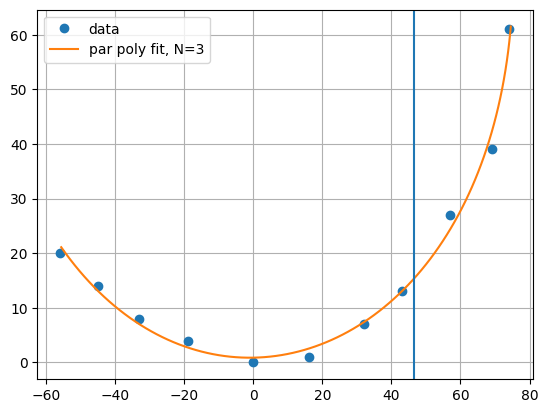

In [2179]:
fig, ax = plt.subplots()
ax.plot(xvals, zvals, 'o', label='data')
ax.plot(xcontvals, zcontvals, '-', label='par poly fit, N=3')
ax.axvline(x_cl_rel)

ax.legend()
ax.grid()
plt.show()

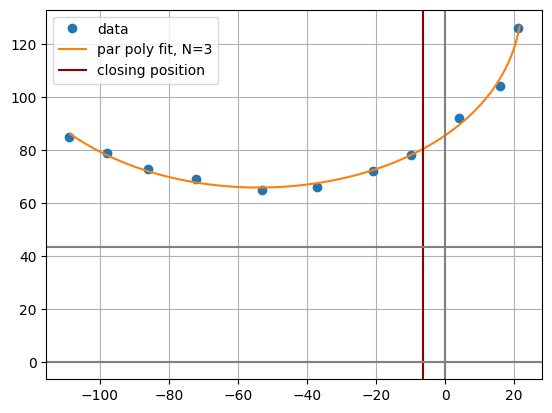

In [2180]:
fig, ax = plt.subplots()
ax.plot(xvals-DC/2, zvals+H-L, 'o', label='data')
ax.plot(xcontvals_abs, zcontvals_abs, '-', label='par poly fit, N=3')
ax.axvline(x_cl_rel-DC/2,color="darkred",label="closing position")
ax.axvline(0,color="gray")
ax.axhline(0,color="gray")
ax.axhline(H0,color="gray")

ax.legend()
ax.grid()
plt.show()

Kör geometria - Dmin

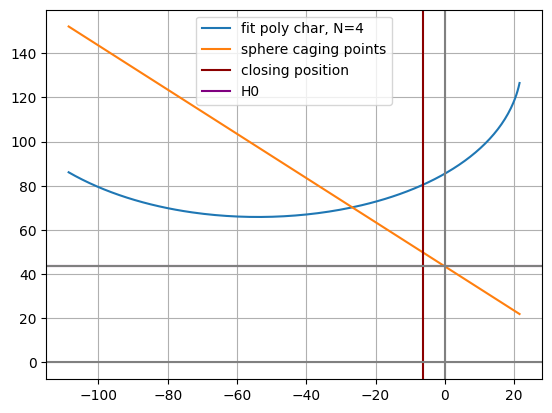

In [2181]:
z_sph = -xcontvals_abs+H0

fig, ax = plt.subplots()

ax.plot(xcontvals_abs, zcontvals_abs, '-', label='fit poly char, N=4')
ax.plot(xcontvals_abs, z_sph, '-', label='sphere caging points')
ax.axvline(x_cl_abs,label="closing position",color="darkred")
ax.axhline(H0,label="H0",color="purple")
ax.axvline(0,color="gray")
ax.axhline(0,color="gray")
ax.axhline(H0,color="gray")

ax.legend()
ax.grid()
plt.show()

In [2182]:
# Define symbolic variables
t_sym, H0_sym, Dc_sym, H_sym, L_sym = sp.symbols("t H0 Dc H L")
a3, a2, a1, a0 = sp.symbols("a3 a2 a1 a0")
b3, b2, b1, b0 = sp.symbols("b3 b2 b1 b0")

# Define parametric polynomials in the relative coordinate system
x_rel = a3*t_sym**3 + a2*t_sym**2 + a1*t_sym + a0
z_rel = b3*t_sym**3 + b2*t_sym**2 + b1*t_sym + b0

# Transform to the absolute coordinate system
x_abs = x_rel - Dc_sym/2
z_abs = z_rel + H_sym - L_sym


# Define the intersection equation
eq1 = sp.Eq(z_abs, -x_abs+H0)

print(eq1)

# Substitute numerical values
subs_dict = {
    H0_sym: H0,
    H_sym: H,
    Dc_sym: DC,
    L_sym: L,
    a3: xcoeffs[0],
    a2: xcoeffs[1],
    a1: xcoeffs[2],
    a0: xcoeffs[3],
    b3: zcoeffs[0],
    b2: zcoeffs[1],
    b1: zcoeffs[2],
    b0: zcoeffs[3]
}

eq1_num = eq1.subs(subs_dict)

# Solve the intersection equation
sol1 = sp.solve(eq1_num, t_sym)

# Calculate intersection coordinates in the absolute coordinate system
intersection_points = [
    (
        float(sp.N(x_abs.subs(subs_dict).subs(t_sym, value))),
        float(sp.N(z_abs.subs(subs_dict).subs(t_sym, value)))
    )
    for value in sol1
    if abs(float(sp.im(sp.N(value)))) < 1e-8
]

print("Parameter solutions:", sol1)
print("Intersection points:", intersection_points)

#display(eq1)
#display(eq1_num)

Dmin = 2*abs(intersection_points[1][0])
print(f"Minimal cageable diameter: {Dmin} mm")


Eq(H - L + b0 + b1*t + b2*t**2 + b3*t**3, Dc/2 - a0 - a1*t - a2*t**2 - a3*t**3 + 43.5)
Parameter solutions: [-0.463008962798599, 0.525267366113024, 2.24637037081405]
Intersection points: [(-133.43758337217687, 176.93758337217696), (-26.733526938790224, 70.23352693879033), (-487.03222786453466, 530.5322278645348)]
Minimal cageable diameter: 53.46705387758045 mm


Henger geometria - Dmin

In [2183]:
H02 = 75

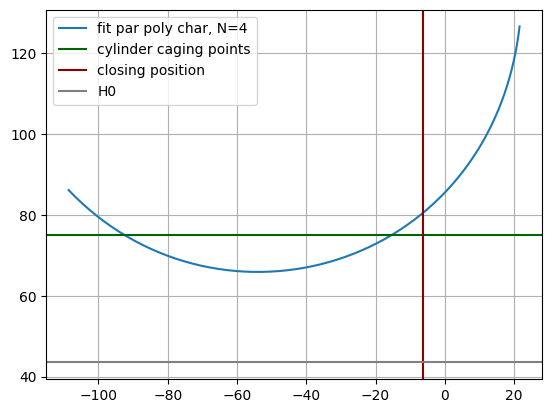

In [2184]:
fig, ax = plt.subplots()

ax.plot(xcontvals_abs, zcontvals_abs, '-', label='fit par poly char, N=4')
ax.axhline(H02, label='cylinder caging points',color="darkgreen")
ax.axvline(x_cl_abs,label="closing position",color="darkred")
ax.axhline(H0,label="H0",color="gray")

ax.legend()
ax.grid()
plt.show()

In [2185]:
H02_sym = sp.Symbol("H02")

eq2 = sp.Eq(z_abs, H02_sym)

subs_dict2 = {
    H0_sym: H0,
    H02_sym:H02,
    H_sym: H,
    Dc_sym: DC,
    L_sym: L,
    a3: xcoeffs[0],
    a2: xcoeffs[1],
    a1: xcoeffs[2],
    a0: xcoeffs[3],
    b3: zcoeffs[0],
    b2: zcoeffs[1],
    b1: zcoeffs[2],
    b0: zcoeffs[3]
}

eq2_num = eq2.subs(subs_dict2)

# Solve the intersection equation
sol2 = sp.solve(eq2_num, t_sym)

# Calculate intersection coordinates in the absolute coordinate system
intersection_points2 = [
    (
        float(sp.N(x_abs.subs(subs_dict).subs(t_sym, value))),
        float(sp.N(z_abs.subs(subs_dict).subs(t_sym, value)))
    )
    for value in sol2
    if abs(float(sp.im(sp.N(value)))) < 1e-8
]

print("Parameter solutions:", sol2)
print("Intersection points:", intersection_points2)

#display(eq1)
#display(eq1_num)

Dmin2 = 2*abs(intersection_points2[1][0])
print(f"Minimal cageable diameter: {Dmin2} mm")

Parameter solutions: [0.115867590294320, 0.601616961306547, 12.1936094856435]
Intersection points: [(-92.50642484017456, 75.00000000000004), (-15.346580152573072, 75.00000000000009), (-177527.80215948398, 74.99999999989632)]
Minimal cageable diameter: 30.693160305146144 mm


Kör geometria - Dmax

In [2186]:
xvals_vac, zvals_vac = np.loadtxt("txtfiles/MEAS_VACUUM_CHAR.txt", delimiter="\t", unpack=True)

(tvals_vac,xcoeffs_vac,zcoeffs_vac,xpoly_vac,
 zpoly_vac,tcontvals_vac,xcontvals_vac,zcontvals_vac) = fit_par_poly(xvals_vac,zvals_vac,degree=3)

xcontvals_abs = xcontvals-DC/2
zcontvals_abs = zcontvals+H-L

print(xcoeffs)
print(xpoly)

[-107.75712617  110.21036207  127.73292678  -55.61851592]
        3         2
-107.8 x + 110.2 x + 127.7 x - 55.62


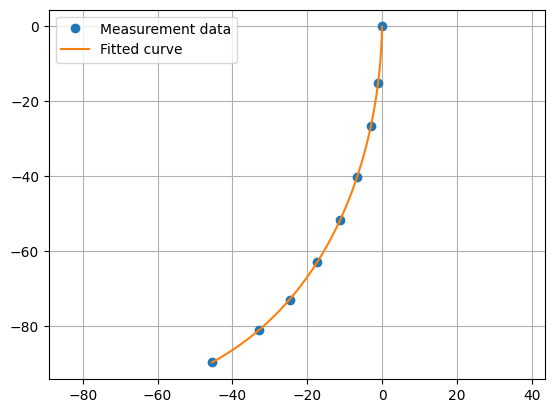

In [2187]:



plt.plot(xvals_vac, zvals_vac, "o", label="Measurement data")
plt.plot(xcontvals_vac, zcontvals_vac, "-", label="Fitted curve")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

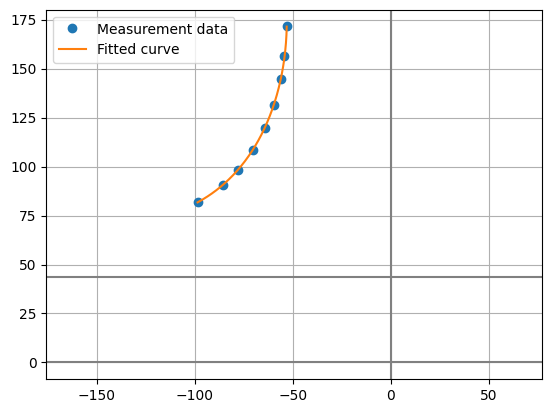

In [2188]:
xcontvals_vac_abs = xcontvals_vac-DC/2
zcontvals_vac_abs = zcontvals_vac+H1

fig,ax = plt.subplots()
ax.plot(xvals_vac-DC/2, zvals_vac+H1, "o", label="Measurement data")
ax.plot(xcontvals_vac_abs, zcontvals_vac_abs, "-", label="Fitted curve")
ax.axhline(H0,color="gray")
ax.axhline(0,color="gray")
ax.axvline( 0,color="gray")

ax.axis("equal")
ax.grid(True)
ax.legend()



In [2189]:
# Symbolic variables
Dmax_sym, H1_sym = sp.symbols("Dmax H1", real=True)

x_rel = a3*t_sym**3 + a2*t_sym**2 + a1*t_sym + a0
z_rel = b3*t_sym**3 + b2*t_sym**2 + b1*t_sym + b0

# Transform to absolute coordinates
x_abs3 = x_rel - Dc_sym/2
z_abs3 = z_rel + H1_sym

# Derivatives with respect to the parameter
dx_dt = sp.diff(x_abs3, t_sym)
dz_dt = sp.diff(z_abs3, t_sym)

# Circle equation:
# center = (0, H0 + Dmax/2), radius = Dmax/2
circle_eq = (
    x_abs3**2
    + (z_abs3 - H0_sym - Dmax_sym/2)**2
    - (Dmax_sym/2)**2
)

# Circle slope: dz/dx = -x / (z - H0 - Dmax/2)
# Tangency condition, avoiding division by dx_dt:
tangent_eq = (
    dz_dt * (z_abs3 - H0_sym - Dmax_sym/2)
    + dx_dt * x_abs3
)

# Substitute numeric values
subs_dict3 = {
    H0_sym: H0,
    H1_sym:H1,
    H_sym: H,
    L_sym: L,
    Dc_sym: DC,
    a3: xcoeffs_vac[0],
    a2: xcoeffs_vac[1],
    a1: xcoeffs_vac[2],
    a0: xcoeffs_vac[3],
    b3: zcoeffs_vac[0],
    b2: zcoeffs_vac[1],
    b1: zcoeffs_vac[2],
    b0: zcoeffs_vac[3],
}

eq_circle_num = circle_eq.subs(subs_dict3)
eq_tangent_num = tangent_eq.subs(subs_dict3)

# Solve for parameter t and circle diameter Dmax
sol3 = sp.nsolve(
    [eq_circle_num, eq_tangent_num],
    [t_sym, Dmax_sym],
    [0.75, 100.0],
    tol=1e-12,
    maxsteps=200,
    prec=30,
)

print(f"sol3: {sol3}")

t_contact = float(sol3[0])
Dmax = float(sol3[1])

x_contact = float(x_abs3.subs(subs_dict3).subs(t_sym, t_contact))
z_contact = float(z_abs3.subs(subs_dict3).subs(t_sym, t_contact))

print(f"t_contact = {t_contact:.8f}")
print(f"Dmax = {Dmax:.8f}")
print(f"Contact point: x = {x_contact:.8f}, z = {z_contact:.8f}")

sol3: Matrix([[0.409666743440028972414339812514], [128.286485439559844990699789167]])
t_contact = 0.40966674
Dmax = 128.28648544
Contact point: x = -60.44533092, z = 129.10757492


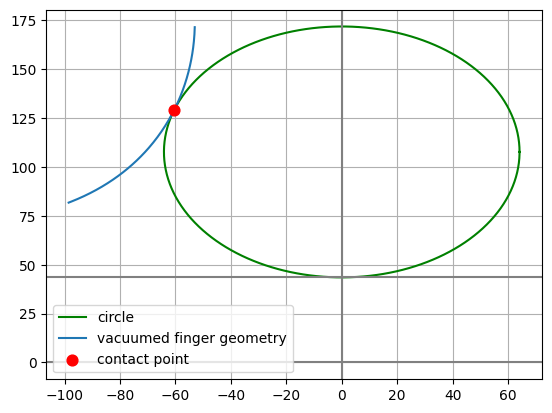

In [2190]:
# Generate circle points
theta = np.linspace(0, 2 * np.pi, 500)
x_circle = 0 + (Dmax/2) * np.cos(theta)
z_circle = H0+Dmax/2 + (Dmax/2) * np.sin(theta)

# Generate parametric polynomial curve (t normalized to [0, 1])
t_plot = np.linspace(0, 1, 500)




fig,ax = plt.subplots()

ax.plot(x_circle, z_circle, label="circle", color="green")
ax.plot(xcontvals_vac_abs, zcontvals_vac_abs,label="vacuumed finger geometry")
ax.axhline(H0,color="gray")
ax.axhline(0,color="gray")
ax.axvline(0,color="gray")
ax.scatter(
    [x_contact], [z_contact],
    color="red", s=60, zorder=5, label="contact point"
)

ax.grid()
ax.legend()

Henger geometria - Dmax

In [2191]:
HCYL = 20

In [2192]:
# Symbolic variables
Dmax_cyl_sym, Hcyl_sym = sp.symbols("Dcyl Hcyl", real=True)


# center = (0, H0 + Dmax/2), radius = Dmax/2
eq4 = (
    z_abs3+2*Hcyl_sym/Dmax_cyl_sym*x_abs3-H02_sym
)
eq4_2 = (a3*t_sym**3+a2*t_sym**2+a1*t_sym+a0-(x_abs3+Dmax_cyl_sym/2))

# Substitute numeric values
subs_dict4 = {
    Hcyl_sym: HCYL,
    H0_sym: H0,
    H02_sym: H02,
    H1_sym:H1,
    H_sym: H,
    Dc_sym: DC,
    a3: xcoeffs_vac[0],
    a2: xcoeffs_vac[1],
    a1: xcoeffs_vac[2],
    a0: xcoeffs_vac[3],
    b3: zcoeffs_vac[0],
    b2: zcoeffs_vac[1],
    b1: zcoeffs_vac[2],
    b0: zcoeffs_vac[3],
}

eq4_num = eq4.subs(subs_dict4)
eq4_2_num = eq4_2.subs(subs_dict4)

# Solve for parameter t and circle diameter Dmax
sol4 = sp.nsolve(
    [eq4_num,eq4_2_num],
    [t_sym,Dmax_cyl_sym],
    [0.75,50],
    tol=1e-12,
    maxsteps=200,
    prec=30,
)

print(f"sol4: {sol4}")

t_contact_cyl = float(sol4[0])
Dmax_cyl = float(sol4[1])

x_contact_cyl = float(x_abs3.subs(subs_dict3).subs(t_sym, t_contact_cyl))
z_contact_cyl = float(z_abs3.subs(subs_dict3).subs(t_sym, t_contact_cyl))

print(f"t_contact = {t_contact_cyl:.8f}")
print(f"Dmax_cyl = {Dmax_cyl:.8f}")
print(f"Contact point: x = {x_contact_cyl:.8f}, z = {z_contact_cyl:.8f}")

sol4: Matrix([[0.691301788584221362742691346139], [106.000000000000000000000000000]])
t_contact = 0.69130179
Dmax_cyl = 106.00000000
Contact point: x = -74.17460116, z = 102.99041553


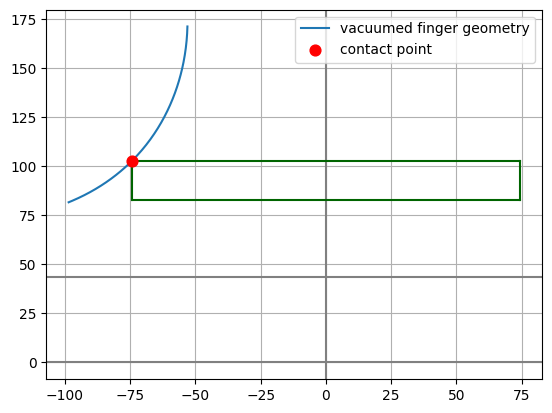

In [2193]:
fig,ax = plt.subplots()

ax.plot(xcontvals_vac_abs, zcontvals_vac_abs,label="vacuumed finger geometry")
ax.axhline(H0,color="gray")
ax.axhline(0,color="gray")
ax.axvline(0,color="gray")
ax.scatter(
    [x_contact_cyl], [z_contact_cyl],
    color="red", s=60, zorder=5, label="contact point"
)
ax.plot([-x_contact_cyl,x_contact_cyl],[z_contact_cyl,z_contact_cyl],color="darkgreen")
ax.plot([-x_contact_cyl,x_contact_cyl],[z_contact_cyl-HCYL,z_contact_cyl-HCYL],color="darkgreen")
ax.plot([-x_contact_cyl,-x_contact_cyl],[z_contact_cyl,z_contact_cyl-HCYL],color="darkgreen")
ax.plot([x_contact_cyl,x_contact_cyl],[z_contact_cyl,z_contact_cyl-HCYL],color="darkgreen")
ax.grid()
ax.legend()